1. IMPORT LIBRARY

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from prophet import Prophet

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

Importing plotly failed. Interactive plots will not work.


2. LOAD DATASET

In [2]:
file_path = "dataset/data_clean.xlsx"

df = pd.read_excel(
    file_path,
    sheet_name="indomie"
)

df.head()

,ds,y
0,2023-01-01,6
1,2023-01-02,11
2,2023-01-03,7
3,2023-01-04,4
4,2023-01-05,7


3. PREPRCESSING DATA

In [3]:
#Konversi Tanggal
df['ds'] = pd.to_datetime(df['ds'])

In [4]:
#urutkan data
df = df.sort_values('ds')

In [5]:
#cek missing value
df = df.sort_values('ds')
df = df.dropna()

In [6]:
#cek data duplikat
df.duplicated().sum()

0

In [7]:
#statistik deskriptif
df['y'].describe()

count    1092.000000
mean        8.585165
std         5.482501
min         0.000000
25%         5.000000
50%         8.000000
75%        10.000000
max        81.000000
Name: y, dtype: float64

In [8]:
#jumlah data 0
print(
    "Jumlah data 0:",
    (df['y'] == 0).sum()
)

Jumlah data 0: 5


4. VISUALISASI PENJUALAN

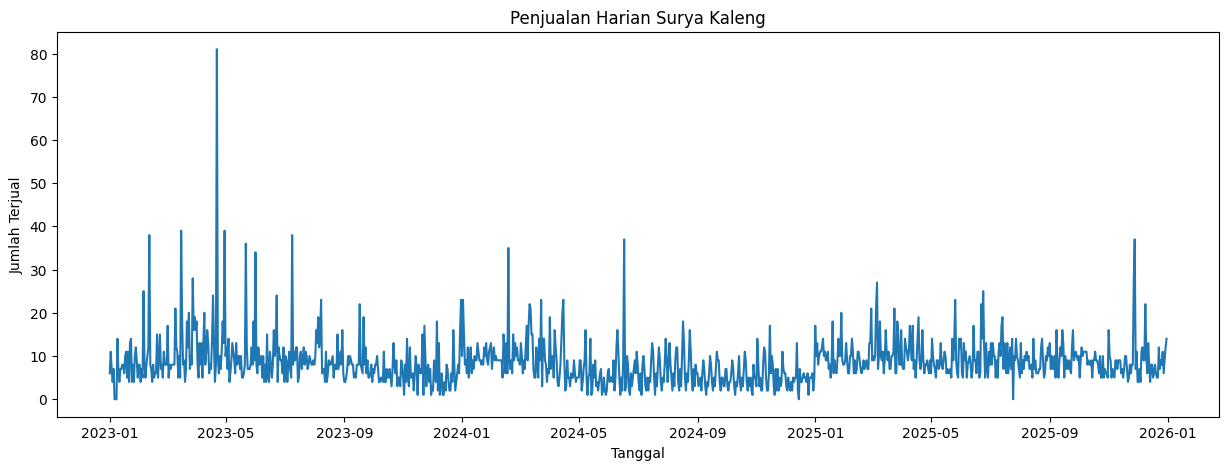

In [9]:
plt.figure(figsize=(15,5))

plt.plot(
    df['ds'],
    df['y']
)

plt.title("Penjualan Harian Surya Kaleng")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah Terjual")

plt.show()

5. ANALISIS PERTAHUN

In [10]:
df['tahun'] = df['ds'].dt.year

df.groupby('tahun')['y'].mean()

tahun
2023    9.112329
2024    7.104972
2025    9.526027
Name: y, dtype: float64

6. SPLIT DATA

In [11]:
train = df[
    df['ds'] < '2025-07-01'
]

test = df[
    df['ds'] >= '2025-07-01'
]

print("Train :", len(train))
print("Test :", len(test))

Train : 908
Test : 184


7. MEMBANGUN MODEL PROPHET

In [12]:
model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True
)

model.fit(train)

19:35:58 - cmdstanpy - INFO - Chain [1] start processing
19:35:58 - cmdstanpy - INFO - Chain [1] done processing


8. PREDIKSI DATA TEST

In [13]:
future = model.make_future_dataframe(
    periods=len(test),
    freq='D'
)

forecast = model.predict(future)

In [14]:
#AMBIL PREDIKISI DATA TEST
pred_test = forecast[
    ['ds','yhat']
]

pred_test = pred_test[
    pred_test['ds'].isin(
        test['ds']
    )
]

9. EVALUASI MODEL

In [15]:
evaluation = test.merge(
    pred_test,
    on='ds'
)

In [16]:
mae = mean_absolute_error(
    evaluation['y'],
    evaluation['yhat']
)

rmse = np.sqrt(
    mean_squared_error(
        evaluation['y'],
        evaluation['yhat']
    )
)

smape = np.mean(
    2 * np.abs(
        evaluation['y'] -
        evaluation['yhat']
    )
    /
    (
        np.abs(evaluation['y']) +
        np.abs(evaluation['yhat'])
    )
) * 100

print("MAE :", round(mae))
print("RMSE :", round(rmse))
print("SMAPE :", round(smape,2), "%")

MAE : 3
RMSE : 4
SMAPE : 30.43 %


10. VISUALISASI AKTUAL VS PREDIKSI

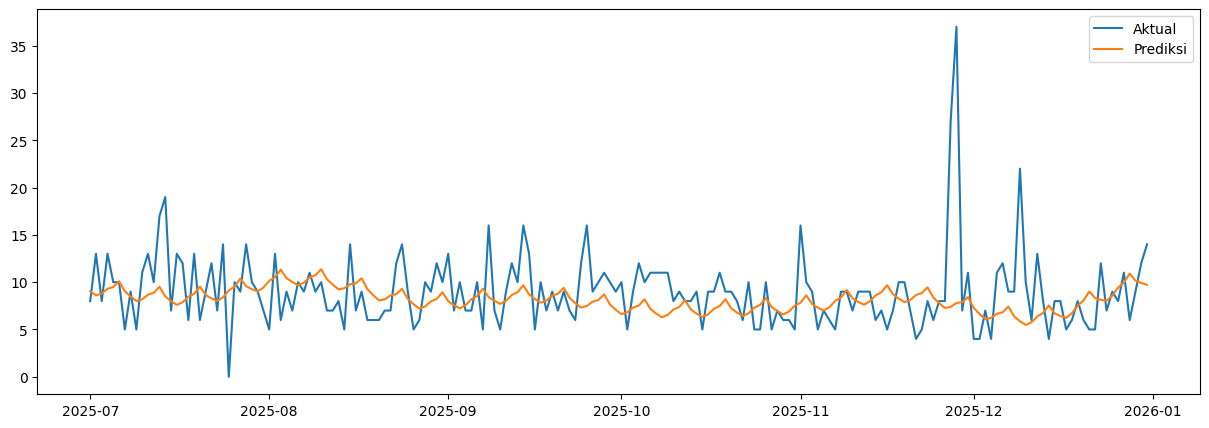

In [17]:
plt.figure(figsize=(15,5))

plt.plot(
    evaluation['ds'],
    evaluation['y'],
    label='Aktual'
)

plt.plot(
    evaluation['ds'],
    evaluation['yhat'],
    label='Prediksi'
)

plt.legend()

plt.show()

11. ANALISIS EROR TERBESAR

In [18]:
evaluation['error'] = abs(
    evaluation['y'] -
    evaluation['yhat']
)

evaluation.sort_values(
    'error',
    ascending=False
).head(20)

,ds,y,tahun,yhat,error
150,2025-11-28,37,2025,7.792767,29.207233
149,2025-11-27,27,2025,7.384112,19.615888
161,2025-12-09,22,2025,5.869465,16.130535
13,2025-07-14,19,2025,8.495587,10.504413
24,2025-07-25,0,2025,9.120031,9.120031
86,2025-09-25,16,2025,7.477362,8.522638
123,2025-11-01,16,2025,7.838594,8.161406
69,2025-09-08,16,2025,8.418702,7.581298
12,2025-07-13,17,2025,9.515390,7.484610
164,2025-12-12,13,2025,6.382445,6.617555


12. TRAINING FINAL MENGGUNAKAN SELURUH DATA

In [19]:
final_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True
)

final_model.fit(df[['ds','y']])

19:35:59 - cmdstanpy - INFO - Chain [1] start processing
19:35:59 - cmdstanpy - INFO - Chain [1] done processing


13. PERAMALAN 14 HARI KEDEPAN

In [20]:
future = final_model.make_future_dataframe(
    periods=14,
    freq='D'
)

forecast = final_model.predict(
    future
)

In [21]:
forecast_14 = forecast[
    ['ds','yhat']
].tail(14)

forecast_14

,ds,yhat
1092,2026-01-01,10.613103
1093,2026-01-02,11.313280
1094,2026-01-03,11.757359
1095,2026-01-04,12.400316
1096,2026-01-05,11.707549
1097,2026-01-06,11.346664
1098,2026-01-07,11.119106
1099,2026-01-08,11.538103
1100,2026-01-09,12.114992
1101,2026-01-10,12.438873


14. HITUNG REKOMENDASI PEMBELIAN

In [22]:
total_forecast = round(
    forecast_14['yhat'].sum()
)

print(
    "Kebutuhan stok 14 hari:",
    total_forecast
)

Kebutuhan stok 14 hari: 165


In [23]:
#TAMBAH SAFETY STOK 10%
stok_beli = round(
    total_forecast * 1.10
)

print(
    "Rekomendasi pembelian:",
    stok_beli
)

Rekomendasi pembelian: 182
